# FSI visualization

Set `SIMULATIONS` to one or more case names saved under `code/cases/outputs/<name>/<name>.npz`, or pass explicit `.npz` paths. The final-state cells plot pressure-cell-centered fluid velocity, the deformed solid, and fluid vorticity.

The frame and video cells are disabled by default. Set `MAKE_STATE_FRAMES = True` to write PNG states, then `MAKE_VIDEO = True` to assemble them with `ffmpeg`.

In [57]:
from pathlib import Path
import re
import shutil
import subprocess
import sys

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection


def find_project_root(start=Path.cwd()):
    start = Path(start).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "code" / "immersed_fsi").is_dir():
            return candidate
    raise RuntimeError("Could not find the project root containing code/immersed_fsi.")


PROJECT_ROOT = find_project_root()
CODE_DIR = PROJECT_ROOT / "code"
if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))

from immersed_fsi.fluid import cell_centered_velocity, cell_centered_vorticity
from immersed_fsi.geometry import point_matrix, quadrilateral_connectivity, triangle_connectivity
from immersed_fsi.io import load_results, parse_float, parse_int


# Names such as "falling_square" or "falling_cylinder", or explicit .npz paths.
# SIMULATIONS = ["falling_square_id", "falling_square_ib", "falling_square_mix"]
# LABELS = ["ID", "IB", "MIX"]
SIMULATIONS = ["falling_cylinder_id", "falling_cylinder_ib", "falling_cylinder_ib_solid",]
LABELS = ["ID", "IB", "SOL"]

OUTPUT_ROOT = CODE_DIR / "cases" / "outputs"
FIGURE_ROOT = CODE_DIR / "plots" / "figures"
STATE_ROOT = CODE_DIR / "plots" / "states"
VIDEO_ROOT = CODE_DIR / "plots" / "videos"

# Set to None for an automatic stride based on grid size.
QUIVER_STRIDE = None
SOLID_FACECOLOR = "#f2a65a"
SOLID_EDGECOLOR = "black"
SOLID_ALPHA = 0.62

# Fixed figure geometry for videos. Keep these constant frame to frame so
# changing colorbar tick labels do not move the images around.
FIGURE_SIZE = (14, 5)
AX_VELOCITY_POS = [0.055, 0.145, 0.365, 0.73]
CAX_VELOCITY_POS = [0.435, 0.145, 0.018, 0.73]
AX_VORTICITY_POS = [0.545, 0.145, 0.365, 0.73]
CAX_VORTICITY_POS = [0.925, 0.145, 0.018, 0.73]

FIGURE_ROOT.mkdir(parents=True, exist_ok=True)
STATE_ROOT.mkdir(parents=True, exist_ok=True)
VIDEO_ROOT.mkdir(parents=True, exist_ok=True)

PROJECT_ROOT

PosixPath('/Users/gabrielemarchi/Desktop/FSI')

In [58]:
def safe_name(value):
    text = re.sub(r"[^A-Za-z0-9_.-]+", "_", str(value)).strip("_")
    return text or "simulation"


def resolve_result(spec):
    spec_text = str(spec)
    path = Path(spec_text).expanduser()
    candidates = []

    if path.suffix == ".npz":
        candidates.append(path if path.is_absolute() else PROJECT_ROOT / path)
        candidates.append(path if path.is_absolute() else CODE_DIR / path)

    for base in (Path.cwd(), PROJECT_ROOT, CODE_DIR):
        candidate = path if path.is_absolute() else base / path
        if candidate.is_dir():
            candidates.extend(sorted(candidate.glob("*.npz")))
        else:
            candidates.append(candidate)

    name = spec_text.rstrip("/")
    candidates.append(OUTPUT_ROOT / name / f"{name}.npz")
    output_folder = OUTPUT_ROOT / name
    if output_folder.is_dir():
        candidates.extend(sorted(output_folder.glob("*.npz")))
    candidates.extend(sorted(OUTPUT_ROOT.glob(f"**/{name}.npz")))
    candidates.extend(sorted(path for path in OUTPUT_ROOT.glob("**/*.npz") if path.stem == name))

    seen = set()
    for candidate in candidates:
        candidate = candidate.resolve()
        if candidate in seen:
            continue
        seen.add(candidate)
        if candidate.is_file() and candidate.suffix == ".npz":
            return candidate

    raise FileNotFoundError(f"Could not resolve simulation {spec!r} under {OUTPUT_ROOT}.")


def load_case(spec, label=None):
    npz_path = resolve_result(spec)
    loaded = load_results(npz_path)
    case_name = loaded.params.get("case_name") or npz_path.stem
    return {
        "spec": spec,
        "name": label or npz_path.stem,
        "case_name": case_name,
        "file_name": npz_path.stem,
        "path": npz_path,
        "params": loaded.params,
        "arrays": loaded.arrays,
    }


def load_cases(simulations, labels=None):
    labels = list(labels or [])
    loaded = []
    for index, spec in enumerate(simulations):
        label = labels[index] if index < len(labels) and labels[index] else None
        loaded.append(load_case(spec, label=label))
    return loaded


def selected_cases(cases, specs):
    if specs is None:
        return list(cases)
    if isinstance(specs, (str, Path)):
        specs = [specs]
    wanted = {str(spec) for spec in specs}
    selected = []
    for case in cases:
        aliases = {
            str(case["spec"]),
            str(case["name"]),
            case["path"].stem,
            str(case["path"]),
        }
        if aliases & wanted:
            selected.append(case)
    if not selected:
        raise ValueError(f"No loaded simulations match {specs!r}.")
    return selected


def parse_simple_yaml_scalar(value):
    value = value.strip()
    if not value:
        return ""
    if value[0] in {"'", '"'} and value[-1:] == value[0]:
        return value[1:-1]
    lowered = value.lower()
    if lowered in {"true", "false"}:
        return lowered == "true"
    try:
        return int(value)
    except ValueError:
        pass
    try:
        return float(value)
    except ValueError:
        return value


def minimal_yaml_load(text):
    root = {}
    stack = [(-1, root)]
    for raw_line in text.splitlines():
        line = raw_line.split("#", 1)[0].rstrip()
        if not line.strip():
            continue
        indent = len(line) - len(line.lstrip(" "))
        stripped = line.strip()
        if ":" not in stripped:
            continue
        key, value = stripped.split(":", 1)
        key = key.strip()
        value = value.strip()
        while indent <= stack[-1][0]:
            stack.pop()
        parent = stack[-1][1]
        if value == "":
            child = {}
            parent[key] = child
            stack.append((indent, child))
        else:
            parent[key] = parse_simple_yaml_scalar(value)
    return root


def case_config(case):
    config_path = case.get("params", {}).get("config_path", "")
    if not config_path:
        return {}
    path = Path(config_path).expanduser()
    candidates = [path] if path.is_absolute() else [PROJECT_ROOT / path, CODE_DIR / path, Path.cwd() / path]
    for candidate in candidates:
        if candidate.exists():
            text = candidate.read_text()
            try:
                import yaml

                return yaml.safe_load(text) or {}
            except Exception:
                return minimal_yaml_load(text)
    return {}


def config_value(config, section_name, key, default=None):
    section_data = config.get(section_name, {}) if isinstance(config, dict) else {}
    return section_data.get(key, default) if isinstance(section_data, dict) else default


def solid_history_length(case):
    arrays = case["arrays"]
    lengths = []
    for key in ("u_s", "v_s", "a_s"):
        if key in arrays and np.asarray(arrays[key]).ndim == 2:
            lengths.append(np.asarray(arrays[key]).shape[0])
    return min(lengths) if lengths else 1


def case_saved_steps(case, n_frames):
    params = case["params"]
    config = case_config(case)
    history_stride = parse_int(
        params,
        "history_stride",
        config_value(config, "time", "history_stride", 1),
    )
    nt = parse_int(params, "Nt", config_value(config, "time", "Nt", None))

    frame_steps = case["arrays"].get("frame_indices")
    if frame_steps is not None:
        steps = np.asarray(frame_steps, dtype=float).reshape(-1)[:n_frames]
    else:
        stride = 1 if history_stride is None else max(1, int(history_stride))
        steps = np.arange(n_frames, dtype=float) * stride
        if nt is not None and n_frames > 1:
            steps[-1] = float(nt)
    return steps


def array_at_frame(case, base_name, frame=-1):
    arrays = case["arrays"]
    final_name = f"{base_name}_final"
    if frame in (-1, None, "final") and final_name in arrays:
        return np.asarray(arrays[final_name])
    if base_name in arrays:
        values = np.asarray(arrays[base_name])
        if values.ndim >= 3:
            return values[frame]
        if base_name in {"u_s", "v_s", "a_s"} and values.ndim == 2:
            return values[frame]
        return values
    if final_name in arrays:
        return np.asarray(arrays[final_name])
    raise KeyError(f"{case['name']} is missing {base_name!r} or {final_name!r}.")


def history_length(case):
    arrays = case["arrays"]
    lengths = []
    for key in ("u_f", "v_f", "p_f"):
        if key in arrays and np.asarray(arrays[key]).ndim >= 3:
            lengths.append(np.asarray(arrays[key]).shape[0])
    for key in ("u_s", "v_s", "a_s"):
        if key in arrays and np.asarray(arrays[key]).ndim == 2:
            lengths.append(np.asarray(arrays[key]).shape[0])
    return min(lengths) if lengths else 1


def frame_indices(case, stride=1, max_frames=None):
    n_frames = history_length(case)
    if n_frames <= 1:
        return [-1]
    stride = max(1, int(stride))
    frames = list(range(0, n_frames, stride))
    if frames[-1] != n_frames - 1:
        frames.append(n_frames - 1)
    if max_frames is not None and len(frames) > max_frames:
        picks = np.linspace(0, len(frames) - 1, int(max_frames)).round().astype(int)
        frames = [frames[i] for i in np.unique(picks)]
    return frames


def fluid_metadata(case):
    params = case["params"]
    u = array_at_frame(case, "u_f", frame=-1)
    fallback_ny = u.shape[0] - 2
    fallback_nx = u.shape[1] - 2
    nx = parse_int(params, "fluid_nx", parse_int(params, "nx_f", fallback_nx))
    ny = parse_int(params, "fluid_ny", parse_int(params, "ny_f", fallback_ny))
    dx = parse_float(params, "fluid_dx", parse_float(params, "dx_f", 1.0 / nx))
    dy = parse_float(params, "fluid_dy", parse_float(params, "dy_f", 1.0 / ny))
    lx = parse_float(params, "fluid_lx", parse_float(params, "lx_f", nx * dx))
    ly = parse_float(params, "fluid_ly", parse_float(params, "ly_f", ny * dy))
    return {"nx": nx, "ny": ny, "dx": dx, "dy": dy, "lx": lx, "ly": ly}


def pressure_cell_grid(meta):
    x = (np.arange(meta["nx"]) + 0.5) * meta["dx"]
    y = (np.arange(meta["ny"]) + 0.5) * meta["dy"]
    return np.meshgrid(x, y, indexing="xy")


def solid_positions(case, frame=-1):
    arrays = case["arrays"]
    if "P_physical" in arrays:
        P = point_matrix(arrays["P_physical"], copy=True)
    else:
        P = point_matrix(arrays["P"], copy=True)
        if "d0_x_s" in arrays and "d0_y_s" in arrays:
            P = P + np.vstack((arrays["d0_x_s"], arrays["d0_y_s"]))

    try:
        u_s = np.asarray(array_at_frame(case, "u_s", frame=frame), dtype=float).reshape(-1)
    except KeyError:
        return P

    nb = P.shape[1]
    if u_s.size != 2 * nb:
        return P
    return P + np.vstack((u_s[:nb], u_s[nb:]))


def solid_polygons(case, frame=-1):
    P = solid_positions(case, frame=frame)
    T = case["arrays"]["T"]
    try:
        elements = triangle_connectivity(T)
    except ValueError:
        elements = quadrilateral_connectivity(T)
    return [P[:, element].T for element in elements]


def add_solid(ax, case, frame=-1):
    collection = PolyCollection(
        solid_polygons(case, frame=frame),
        facecolor=SOLID_FACECOLOR,
        edgecolor=SOLID_EDGECOLOR,
        linewidth=0.55,
        alpha=SOLID_ALPHA,
        zorder=5,
    )
    ax.add_collection(collection)
    return collection


def quiver_stride(meta, requested):
    if requested is not None:
        return max(1, int(requested))
    return max(1, int(max(meta["nx"], meta["ny"]) / 42))

In [59]:
cases = load_cases(SIMULATIONS, LABELS)
for case in cases:
    meta = fluid_metadata(case)
    print(
        f"{case['name']}: {case['path']} | "
        f"fluid {meta['nx']}x{meta['ny']} | saved frames {history_length(case)}"
    )

ID: /Users/gabrielemarchi/Desktop/FSI/code/cases/outputs/falling_cylinder/falling_cylinder_id.npz | fluid 200x50 | saved frames 1
IB: /Users/gabrielemarchi/Desktop/FSI/code/cases/outputs/falling_cylinder/falling_cylinder_ib.npz | fluid 200x50 | saved frames 1
SOL: /Users/gabrielemarchi/Desktop/FSI/code/cases/outputs/falling_cylinder/falling_cylinder_ib_solid.npz | fluid 200x50 | saved frames 1


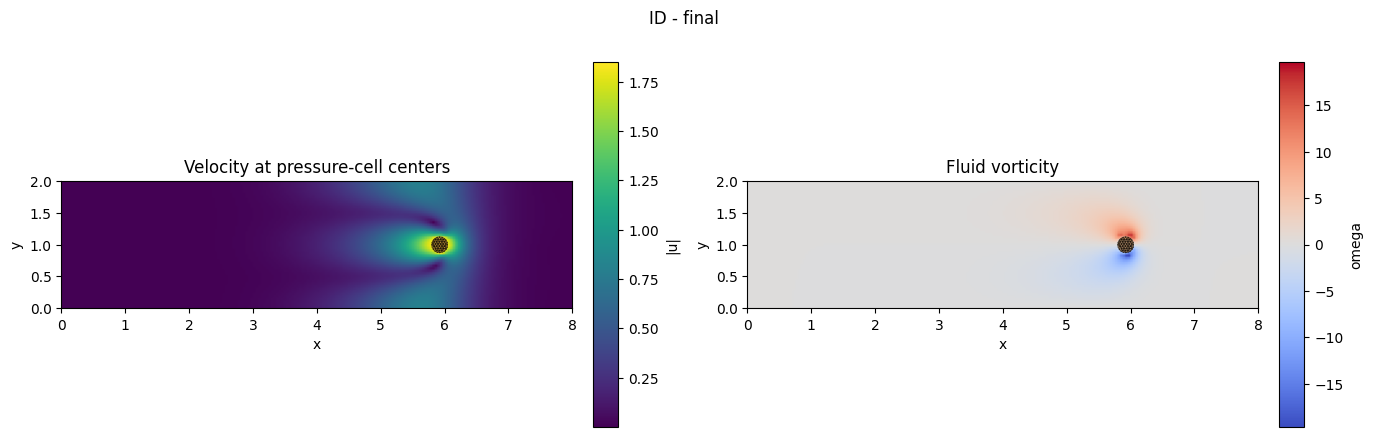

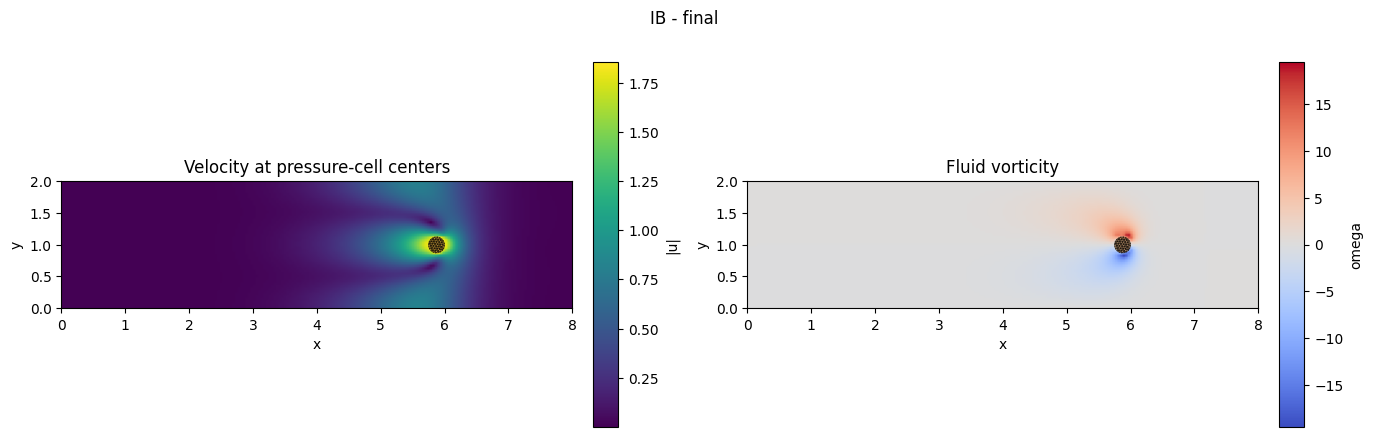

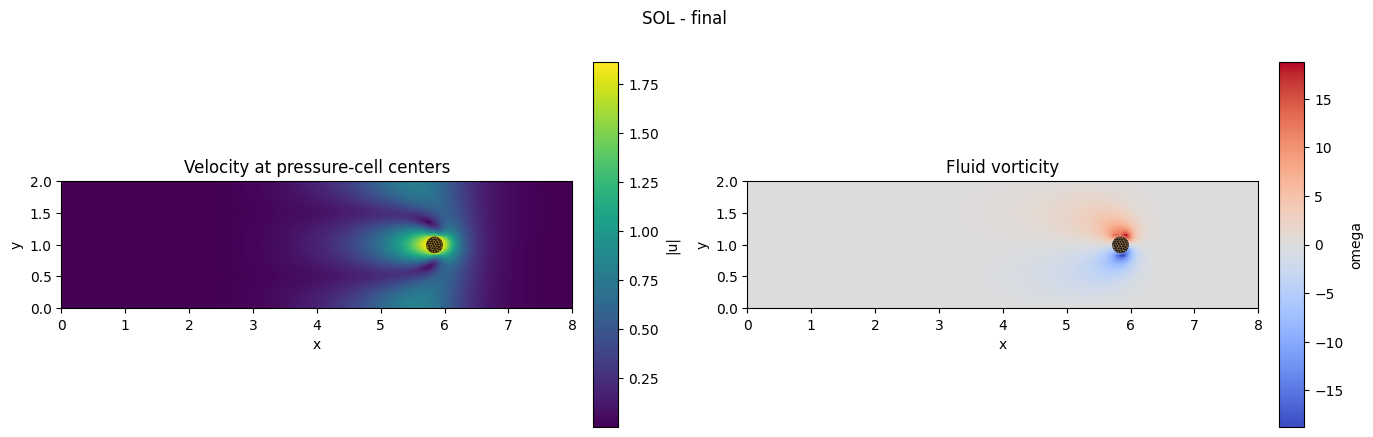

In [60]:
def plot_case_state(case, frame=-1):
    meta = fluid_metadata(case)
    u_f = array_at_frame(case, "u_f", frame=frame)
    v_f = array_at_frame(case, "v_f", frame=frame)
    uc, vc = cell_centered_velocity(u_f, v_f)
    vorticity = cell_centered_vorticity(u_f, v_f, meta["dx"], meta["dy"])
    speed = np.sqrt(uc * uc + vc * vc)
    X, Y = pressure_cell_grid(meta)
    stride = quiver_stride(meta, QUIVER_STRIDE)
    skip = (slice(None, None, stride), slice(None, None, stride))

    fig = plt.figure(figsize=FIGURE_SIZE)
    axes = [fig.add_axes(AX_VELOCITY_POS), fig.add_axes(AX_VORTICITY_POS)]
    cax0 = fig.add_axes(CAX_VELOCITY_POS)
    cax1 = fig.add_axes(CAX_VORTICITY_POS)
    extent = [0.0, meta["lx"], 0.0, meta["ly"]]

    im0 = axes[0].imshow(speed, origin="lower", extent=extent, cmap="viridis")
    # axes[0].quiver(
    #     X[skip],
    #     Y[skip],
    #     uc[skip],
    #     vc[skip],
    #     color="white",
    #     alpha=0.85,
    #     width=0.0022,
    #     pivot="mid",
    # )
    add_solid(axes[0], case, frame=frame)
    axes[0].set_title("Velocity at pressure-cell centers")
    fig.colorbar(im0, cax=cax0, label="|u|")

    vmax = float(np.nanmax(np.abs(vorticity))) if vorticity.size else 1.0
    vmax = vmax if np.isfinite(vmax) and vmax > 0.0 else 1.0
    im1 = axes[1].imshow(
        vorticity,
        origin="lower",
        extent=extent,
        cmap="coolwarm",
        vmin=-vmax,
        vmax=vmax,
    )
    add_solid(axes[1], case, frame=frame)
    axes[1].set_title("Fluid vorticity")
    fig.colorbar(im1, cax=cax1, label="omega")

    frame_label = "final" if frame == -1 else f"frame {frame}"
    fig.suptitle(f"{case['name']} - {frame_label}")
    for ax in axes:
        ax.set_xlim(0.0, meta["lx"])
        ax.set_ylim(0.0, meta["ly"])
        ax.set_aspect("equal", adjustable="box")
        ax.set_xlabel("x")
        ax.set_ylabel("y")
    return fig


for case in cases:
    fig = plot_case_state(case, frame=-1)
    plt.show()

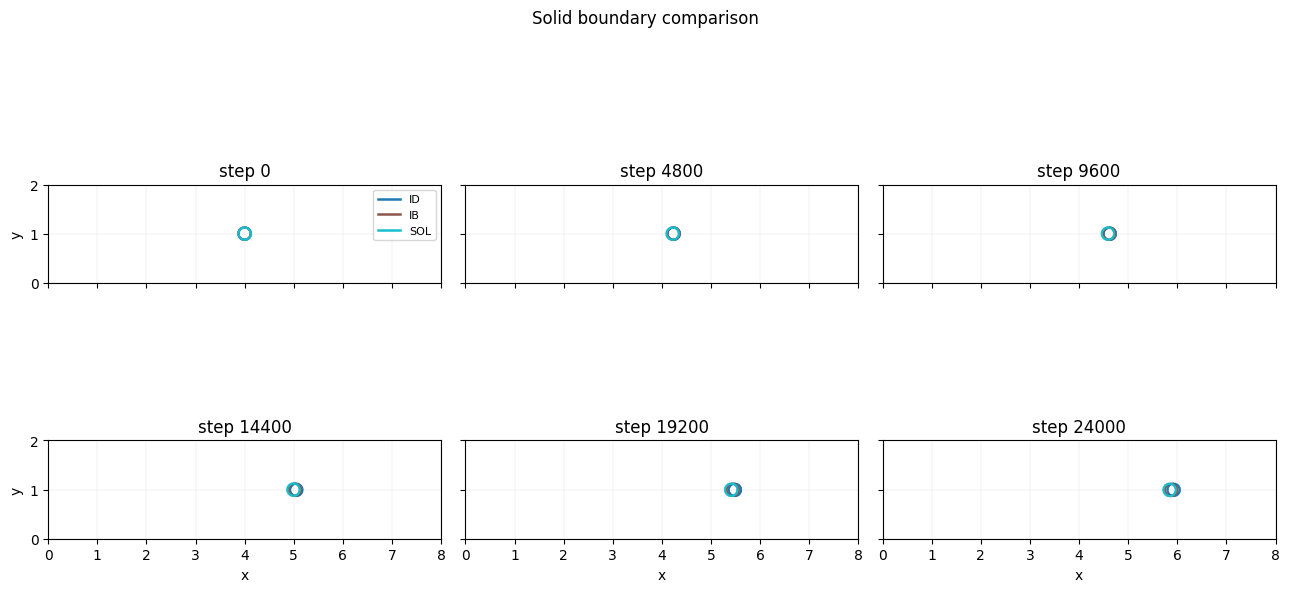

In [61]:
def solid_boundary_segments(case, frame=-1):
    P = solid_positions(case, frame=frame)
    arrays = case["arrays"]
    B = np.asarray(arrays.get("B", arrays.get("bdry")), dtype=int)
    if B.ndim != 2 or B.shape[0] < 4:
        raise ValueError(f"{case['name']} is missing a valid B/bdry boundary array.")
    edges = B[2:4, :].T
    return [(P[0, edge], P[1, edge]) for edge in edges]


def solid_frame_steps(case):
    return case_saved_steps(case, solid_history_length(case))


def comparison_frames(case, n_times=6):
    n_frames = solid_history_length(case)
    if n_frames <= 1:
        return [-1], ["final"], [np.nan]

    steps = solid_frame_steps(case)
    targets = np.linspace(float(steps[0]), float(steps[-1]), n_times)
    frames = [int(np.argmin(np.abs(steps - target))) for target in targets]
    frames[0] = 0
    frames[-1] = n_frames - 1

    labels = [f"step {int(round(steps[frame]))}" for frame in frames]
    targets = [float(steps[frame]) for frame in frames]
    return frames, labels, targets


def nearest_solid_frame(case, target_step):
    n_frames = solid_history_length(case)
    if n_frames <= 1 or not np.isfinite(target_step):
        return -1
    steps = solid_frame_steps(case)
    return int(np.argmin(np.abs(steps - target_step)))


def plot_solid_boundary_comparison(cases, n_times=6):
    reference = cases[0]
    frames, labels, target_steps = comparison_frames(reference, n_times=n_times)
    meta = fluid_metadata(reference)
    colors = plt.cm.tab10(np.linspace(0.0, 1.0, max(len(cases), 3)))

    fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharex=True, sharey=True)
    axes = axes.ravel()
    for ax, frame, label, target_step in zip(axes, frames, labels, target_steps):
        for color, case in zip(colors, cases):
            case_frame = nearest_solid_frame(case, target_step)
            for x_edge, y_edge in solid_boundary_segments(case, frame=case_frame):
                ax.plot(x_edge, y_edge, color=color, linewidth=1.45, alpha=0.95)
            ax.plot([], [], color=color, linewidth=1.8, label=case["name"])

        ax.set_title(label)
        ax.set_aspect("equal", adjustable="box")
        ax.set_xlim(0.0, meta["lx"])
        ax.set_ylim(0.0, meta["ly"])
        ax.grid(True, linewidth=0.35, alpha=0.35)

    for ax in axes[len(frames):]:
        ax.set_axis_off()
    for ax in axes[3:]:
        if ax.axison:
            ax.set_xlabel("x")
    for ax in axes[::3]:
        if ax.axison:
            ax.set_ylabel("y")
    axes[0].legend(loc="best", fontsize=8)
    fig.suptitle("Solid boundary comparison")
    fig.tight_layout()
    return fig


fig = plot_solid_boundary_comparison(cases, n_times=6)
plt.show()


/var/folders/2q/8cxxvqvx75320dg41mcjy10c0000gn/T/ipykernel_22527/2080072141.py:67: RuntimeWarning: divide by zero encountered in matmul
  vx = v_s[:, :nb] @ weights / weights.sum()
/var/folders/2q/8cxxvqvx75320dg41mcjy10c0000gn/T/ipykernel_22527/2080072141.py:67: RuntimeWarning: overflow encountered in matmul
  vx = v_s[:, :nb] @ weights / weights.sum()
/var/folders/2q/8cxxvqvx75320dg41mcjy10c0000gn/T/ipykernel_22527/2080072141.py:67: RuntimeWarning: invalid value encountered in matmul
  vx = v_s[:, :nb] @ weights / weights.sum()
/var/folders/2q/8cxxvqvx75320dg41mcjy10c0000gn/T/ipykernel_22527/2080072141.py:68: RuntimeWarning: divide by zero encountered in matmul
  vy = v_s[:, nb:] @ weights / weights.sum()
/var/folders/2q/8cxxvqvx75320dg41mcjy10c0000gn/T/ipykernel_22527/2080072141.py:68: RuntimeWarning: overflow encountered in matmul
  vy = v_s[:, nb:] @ weights / weights.sum()
/var/folders/2q/8cxxvqvx75320dg41mcjy10c0000gn/T/ipykernel_22527/2080072141.py:68: RuntimeWarning: invalid v

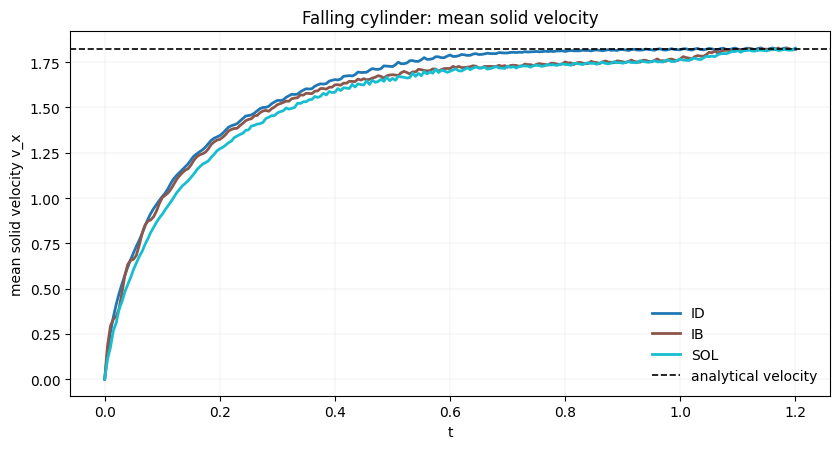

In [62]:
# Falling-cylinder mean solid velocity comparison
def is_falling_cylinder(case):
    tokens = [
        case.get("case_name", ""),
        case.get("file_name", ""),
        case.get("name", ""),
        case.get("params", {}).get("solid_geometry", ""),
    ]
    return any("falling_cylinder" in str(token).lower() for token in tokens)


def case_time_vector(case, n_frames):
    params = case["params"]
    config = case_config(case)
    dt = parse_float(params, "dt", config_value(config, "time", "dt", None))
    steps = case_saved_steps(case, n_frames)
    if dt is None:
        return steps, "saved step"
    return steps * float(dt), "t"


def lumped_node_weights(P, T):
    try:
        elements = triangle_connectivity(T)
        nodes_per_element = 3
    except ValueError:
        elements = quadrilateral_connectivity(T)
        nodes_per_element = 4

    weights = np.zeros(P.shape[1], dtype=float)
    if nodes_per_element == 3:
        x0 = P[0, elements[:, 0]]
        y0 = P[1, elements[:, 0]]
        x1 = P[0, elements[:, 1]]
        y1 = P[1, elements[:, 1]]
        x2 = P[0, elements[:, 2]]
        y2 = P[1, elements[:, 2]]
        areas = 0.5 * np.abs((x1 - x0) * (y2 - y0) - (x2 - x0) * (y1 - y0))
    else:
        pts = np.moveaxis(P[:, elements], 0, -1)
        x = pts[:, :, 0]
        y = pts[:, :, 1]
        areas = 0.5 * np.abs(np.sum(x * np.roll(y, -1, axis=1) - y * np.roll(x, -1, axis=1), axis=1))

    for local_node in range(nodes_per_element):
        np.add.at(weights, elements[:, local_node], areas / nodes_per_element)
    return weights


def mean_solid_velocity(case):
    arrays = case["arrays"]
    if "v_s" in arrays:
        v_s = np.asarray(arrays["v_s"], dtype=float)
    elif "v_s_final" in arrays:
        v_s = np.asarray(arrays["v_s_final"], dtype=float)[None, :]
    else:
        raise KeyError(f"{case['name']} is missing solid velocity arrays.")
    if v_s.ndim == 1:
        v_s = v_s[None, :]

    P = point_matrix(arrays["P"], copy=True)
    weights = lumped_node_weights(P, arrays["T"])
    nb = P.shape[1]
    if v_s.shape[1] != 2 * nb:
        raise ValueError(f"{case['name']} has inconsistent v_s size.")

    vx = v_s[:, :nb] @ weights / weights.sum()
    vy = v_s[:, nb:] @ weights / weights.sum()
    t, x_label = case_time_vector(case, v_s.shape[0])
    return t, vx, vy, x_label


def theoretical_falling_cylinder_velocity(case):
    params = case["params"]
    direct = parse_float(params, "terminal_velocity_analytical", None)
    if direct is not None and np.isfinite(direct):
        return direct

    rho_f = parse_float(params, "fluid_rho", parse_float(params, "rho_f", None))
    rho_s = parse_float(params, "solid_rho", parse_float(params, "rho_s", None))
    mu_f = parse_float(params, "fluid_mu", parse_float(params, "mu_f", None))
    radius = parse_float(params, "solid_radius", parse_float(params, "cylinder_radius", None))
    channel_half_height = parse_float(
        params,
        "L",
        parse_float(params, "fluid_ly", parse_float(params, "ly_f", np.nan)) / 2.0,
    )
    force_density = np.array([
        parse_float(params, "solid_body_force_density_x", 0.0),
        parse_float(params, "solid_body_force_density_y", 0.0),
    ])

    if None in {rho_f, rho_s, mu_f, radius} or not np.isfinite(channel_half_height):
        return np.nan
    density_jump = rho_s - rho_f
    if density_jump == 0.0 or mu_f == 0.0 or radius <= 0.0 or channel_half_height <= 0.0:
        return np.nan

    body_acceleration = force_density / density_jump
    direction = int(np.argmax(np.abs(body_acceleration)))
    body_force = body_acceleration[direction]
    wall_factor = (
        np.log(channel_half_height / radius)
        - 0.9157
        + 1.7244 * (radius / channel_half_height) ** 2
        - 1.7302 * (radius / channel_half_height) ** 4
    )
    return density_jump * body_force * radius**2 * wall_factor / (4.0 * mu_f)


def plot_falling_cylinder_mean_velocity(cases):
    cylinder_cases = [case for case in cases if is_falling_cylinder(case)]
    if not cylinder_cases:
        print("No falling_cylinder cases loaded; skipping mean solid velocity plot.")
        return None

    colors = plt.cm.tab10(np.linspace(0.0, 1.0, max(len(cylinder_cases), 3)))
    fig, ax = plt.subplots(figsize=(8.5, 4.6))
    reference_velocity = np.nan
    x_label = "t"

    for color, case in zip(colors, cylinder_cases):
        t, vx, vy, x_label = mean_solid_velocity(case)
        ax.plot(t, vx, color=color, lw=2.0, label=case["name"])
        if not np.isfinite(reference_velocity):
            reference_velocity = theoretical_falling_cylinder_velocity(case)

    if np.isfinite(reference_velocity):
        ax.axhline(reference_velocity, color="black", ls="--", lw=1.2, label="analytical velocity")

    ax.set_xlabel(x_label)
    ax.set_ylabel("mean solid velocity v_x")
    ax.set_title("Falling cylinder: mean solid velocity")
    ax.grid(True, linewidth=0.35, alpha=0.35)
    ax.legend(frameon=False)
    fig.tight_layout()
    return fig


fig = plot_falling_cylinder_mean_velocity(cases)
if fig is not None:
    plt.show()


## Optional video workflow

The next cell writes one PNG per saved state into `code/plots/states/<simulation>/`. If a result was saved with final-state arrays only, the folder will contain only one frame. For a real video, run the simulation with saved histories, for example by using `output.save_mode: history` or `both` and a reasonable `time.history_stride`.

In [63]:
MAKE_STATE_FRAMES = False
FRAME_SIMULATIONS = SIMULATIONS
FRAME_STRIDE = 10
MAX_FRAMES = None
FRAME_DPI = 150
CLEAR_STATE_FOLDER = True


if MAKE_STATE_FRAMES:
    for case in selected_cases(cases, FRAME_SIMULATIONS):
        folder = STATE_ROOT / safe_name(case["name"])
        if CLEAR_STATE_FOLDER and folder.exists():
            shutil.rmtree(folder)
        folder.mkdir(parents=True, exist_ok=True)

        frames = frame_indices(case, stride=FRAME_STRIDE, max_frames=MAX_FRAMES)
        if frames == [-1]:
            print(f"{case['name']}: only final-state arrays found; writing one frame.")

        for out_index, frame in enumerate(frames):
            fig = plot_case_state(case, frame=frame)
            fig.savefig(folder / f"frame_{out_index:05d}.png", dpi=FRAME_DPI)
            plt.close(fig)

        print(f"{case['name']}: wrote {len(frames)} frame(s) to {folder}")
else:
    print("MAKE_STATE_FRAMES is False. Set it to True to write PNG states.")

MAKE_STATE_FRAMES is False. Set it to True to write PNG states.


In [64]:
MAKE_VIDEO = False
VIDEO_SIMULATIONS = SIMULATIONS
VIDEO_FPS = 24


if MAKE_VIDEO:
    for case in selected_cases(cases, VIDEO_SIMULATIONS):
        frame_folder = STATE_ROOT / safe_name(case["name"])
        if not any(frame_folder.glob("frame_*.png")):
            raise FileNotFoundError(
                f"No frames found in {frame_folder}. Run the state-frame cell first."
            )

        output = VIDEO_ROOT / f"{safe_name(case['name'])}.mp4"
        cmd = [
            "ffmpeg",
            "-y",
            "-framerate",
            str(VIDEO_FPS),
            "-i",
            str(frame_folder / "frame_%05d.png"),
            "-pix_fmt",
            "yuv420p",
            "-vf",
            "pad=ceil(iw/2)*2:ceil(ih/2)*2",
            str(output),
        ]
        print("$ " + " ".join(cmd))
        subprocess.run(cmd, check=True)
        print(f"Wrote {output}")
else:
    print("MAKE_VIDEO is False. Set it to True after generating PNG states.")

MAKE_VIDEO is False. Set it to True after generating PNG states.
